# EN3160 Assignment 1 on Neural Networks

Assignment Done and Submitted by: O.N.H. Imaduwage 230258D 

Github Link:
https://github.com/oshan-imaduwage/EN3160_Assignment_03


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


import torch
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

CUDA Available: True
Device Name: NVIDIA GeForce RTX 4060 Laptop GPU


# Q1

Epoch 1/10, Loss: 1.9501
Epoch 2/10, Loss: 1.7733
Epoch 3/10, Loss: 1.7148
Epoch 4/10, Loss: 1.6766
Epoch 5/10, Loss: 1.6485
Epoch 6/10, Loss: 1.6253
Epoch 7/10, Loss: 1.6057
Epoch 8/10, Loss: 1.5887
Epoch 9/10, Loss: 1.5733
Epoch 10/10, Loss: 1.5596


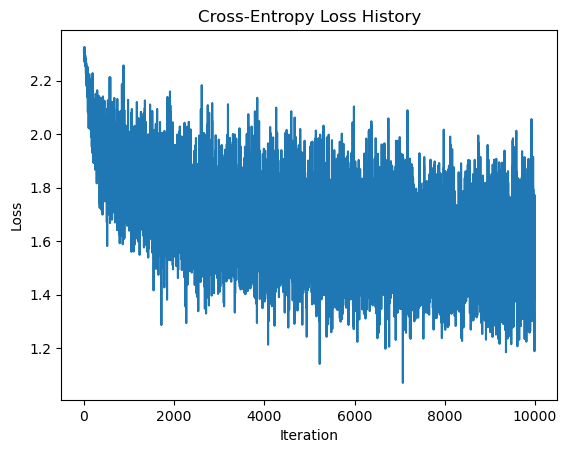

Training accuracy: 46.78%
Test accuracy: 44.88%


In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 1. Network Architecture Dimensions
Din = 3 * 32 * 32  # 3072 input features
H = 100            # (a) Middle layer with 100 nodes
K = 10             # Output classes
# I had to adjust this avoid vanishing gradients, so i did not use the value in the original code
std = 0.02       # Adjusted weight scale for non-zero gradient flow

# Initialize Layer 1 (Din -> H) and Layer 2 (H -> K)
w1 = torch.randn(Din, H, device=device) * std
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * std
b2 = torch.zeros(K, device=device)

# Hyperparameters
iterations = 10    # (c) 10 Epochs
# given lr of 2e-6 was far too small to train anything from 10 epochs, so I adjusted the value
lr = 0.05         # Learning rate suitable for Cross-Entropy
lr_decay = 0.9  
reg = 0
loss_history = []

# 2. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # --- Forward Pass ---
        # Layer 1: Linear + Sigmoid activation
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)

        # Layer 2: Output logits
        scores = h.mm(w2) + b2

        # (b) Cross-Entropy Loss with Softmax
        # Shift logits for numerical stability: max(scores) per row
        shifted_scores = scores - torch.max(scores, dim=1, keepdim=True).values
        exp_scores = torch.exp(shifted_scores)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)

        # Cross-Entropy loss calculation
        loss = -torch.sum(y_train_onehot * torch.log(probs + 1e-12)) / Ntr + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # --- Manual Backpropagation ---
        # 1. Gradient of Cross-Entropy w.r.t. unnormalized logits (scores): dL/dscores = (probs - y) / N
        dscores = (probs - y_train_onehot) / Ntr

        # 2. Backprop into Layer 2 parameters
        dw2 = h.t().mm(dscores) + reg * w2
        db2 = dscores.sum(dim=0)

        # 3. Backprop into hidden layer activation (h)
        dh = dscores.mm(w2.t())

        # 4. Backprop through Sigmoid: dL/dz1 = dh * h * (1 - h)
        dz1 = dh * h * (1.0 - h)

        # 5. Backprop into Layer 1 parameters
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # --- Gradient Descent Update ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / len(trainloader)
    print(f"Epoch {t + 1}/{iterations}, Loss: {epoch_loss:.4f}")
    lr *= lr_decay

# 3. Plot Loss History
plt.plot(loss_history)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 4. Evaluate Training Accuracy
correct_train, total_train = 0, 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        scores = h.mm(w2) + b2
        predicted = torch.argmax(scores, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

print(f"Training accuracy: {100 * correct_train / total_train:.2f}%")

# 5. Evaluate Test Accuracy
correct_test, total_test = 0, 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        z1 = x_test.mm(w1) + b1
        h = torch.sigmoid(z1)
        scores = h.mm(w2) + b2
        predicted = torch.argmax(scores, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

print(f"Test accuracy: {100 * correct_test / total_test:.2f}%")

### Discussion and interpretation

The two-layer network learned from the CIFAR-10 data: its training loss fell from **1.9501** to **1.5596** over 10 epochs. Its final training accuracy was **46.78%**, and its test accuracy was **44.88%**. Since those scores are only 1.90 percentage points apart, the main challenge seems to be the model's ability to classify the images, rather than a large gap between training and test performance. The network also flattens each image into a vector, losing spatial information that a convolutional network could use. Trying a CNN or another more capable architecture would be a sensible next step.

# Q2

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x000002B51C3A00E0>
Traceback (most recent call last):
  File "c:\Users\Oshan\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py", line 1664, in __del__
    self._shutdown_workers()
  File "c:\Users\Oshan\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py", line 1622, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'
100%|██████████| 9.91M/9.91M [00:44<00:00, 223kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 87.1kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 637kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.19MB/s]



--- Training LeNet-5 for 10 Epochs ---
Epoch [01/10] Train Loss: 0.2410 | Train Acc: 93.16% | Test Loss: 0.0788 | Test Acc: 97.54%
Epoch [02/10] Train Loss: 0.0677 | Train Acc: 97.95% | Test Loss: 0.0566 | Test Acc: 98.17%
Epoch [03/10] Train Loss: 0.0476 | Train Acc: 98.52% | Test Loss: 0.0464 | Test Acc: 98.47%
Epoch [04/10] Train Loss: 0.0381 | Train Acc: 98.81% | Test Loss: 0.0485 | Test Acc: 98.58%
Epoch [05/10] Train Loss: 0.0300 | Train Acc: 99.06% | Test Loss: 0.0403 | Test Acc: 98.67%
Epoch [06/10] Train Loss: 0.0239 | Train Acc: 99.27% | Test Loss: 0.0422 | Test Acc: 98.68%
Epoch [07/10] Train Loss: 0.0219 | Train Acc: 99.31% | Test Loss: 0.0399 | Test Acc: 98.78%
Epoch [08/10] Train Loss: 0.0182 | Train Acc: 99.43% | Test Loss: 0.0378 | Test Acc: 98.83%
Epoch [09/10] Train Loss: 0.0148 | Train Acc: 99.50% | Test Loss: 0.0364 | Test Acc: 98.97%
Epoch [10/10] Train Loss: 0.0145 | Train Acc: 99.53% | Test Loss: 0.0401 | Test Acc: 98.76%

--- Training Modern Small CNN for 10 Ep

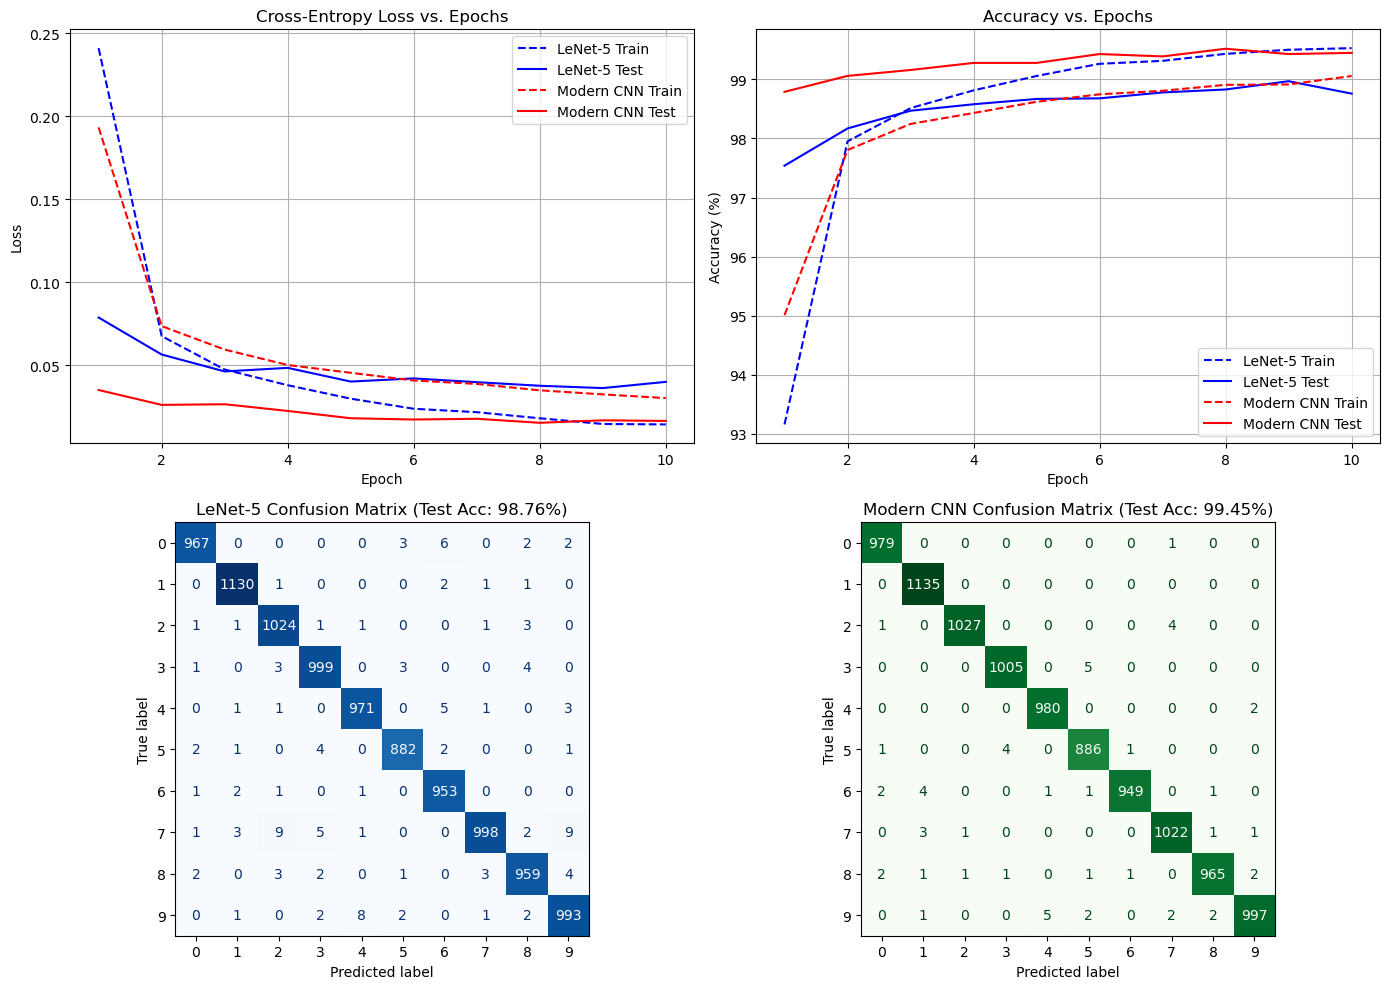

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.Pad(2),  # Pad 28x28 MNIST to 32x32
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# -------------------------------------------------------------------------
# 1. Model Definitions
# -------------------------------------------------------------------------
# (a) Classic LeNet-5 Architecture (AvgPool + Tanh)
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),         # 32x32 -> 28x28 (C1)
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),  # 28x28 -> 14x14 (S2)
            nn.Conv2d(6, 16, kernel_size=5),       # 14x14 -> 10x10 (C3)
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2)   # 10x10 -> 5x5   (S4)
        )
        self.classifier = nn.Sequential(
            nn.Linear(16 * 5 * 5, 120),             # C5: 120
            nn.Tanh(),
            nn.Linear(120, 84),                     # F6: 84
            nn.Tanh(),
            nn.Linear(84, 10)                       # Output: 10
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

# (b) Modern Small CNN (3 Conv layers with BatchNorm and Dropout)
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Conv Layer 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32x32 -> 16x16
            nn.Dropout(0.2),

            # Conv Layer 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 16x16 -> 8x8
            nn.Dropout(0.2),

            # Conv Layer 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 8x8 -> 4x4
            nn.Dropout(0.3)
        )
        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

# -------------------------------------------------------------------------
# 2. Shared Training and Evaluation Pipeline
# -------------------------------------------------------------------------
def train_and_evaluate(model, model_name, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    all_preds, all_targets = [], []

    print(f"\n--- Training {model_name} for {epochs} Epochs ---")
    for epoch in range(epochs):
        # Training Phase
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for data, targets in train_loader:
            data, targets = data.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * data.size(0)
            preds = outputs.argmax(dim=1)
            train_correct += (preds == targets).sum().item()
            train_total += targets.size(0)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = (train_correct / train_total) * 100

        # Evaluation Phase
        model.eval()
        test_loss, test_correct, test_total = 0.0, 0, 0
        with torch.no_grad():
            for data, targets in test_loader:
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)

                test_loss += loss.item() * data.size(0)
                preds = outputs.argmax(dim=1)
                test_correct += (preds == targets).sum().item()
                test_total += targets.size(0)

                if epoch == epochs - 1:
                    all_preds.extend(preds.cpu().numpy())
                    all_targets.extend(targets.cpu().numpy())

        epoch_test_loss = test_loss / test_total
        epoch_test_acc = (test_correct / test_total) * 100

        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['test_loss'].append(epoch_test_loss)
        history['test_acc'].append(epoch_test_acc)

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
              f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")

    return history, np.array(all_targets), np.array(all_preds)

# Run training for both networks
epochs = 10
lenet_history, lenet_targets, lenet_preds = train_and_evaluate(LeNet5(), "LeNet-5", epochs=epochs)
modern_history, modern_targets, modern_preds = train_and_evaluate(ModernCNN(), "Modern Small CNN", epochs=epochs)

# -------------------------------------------------------------------------
# 3. Plotting Training/Test Curves & Confusion Matrices
# -------------------------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Loss curves
axs[0, 0].plot(range(1, epochs + 1), lenet_history['train_loss'], 'b--', label='LeNet-5 Train')
axs[0, 0].plot(range(1, epochs + 1), lenet_history['test_loss'], 'b-', label='LeNet-5 Test')
axs[0, 0].plot(range(1, epochs + 1), modern_history['train_loss'], 'r--', label='Modern CNN Train')
axs[0, 0].plot(range(1, epochs + 1), modern_history['test_loss'], 'r-', label='Modern CNN Test')
axs[0, 0].set_title('Cross-Entropy Loss vs. Epochs')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()
axs[0, 0].grid(True)

# Subplot 2: Accuracy curves
axs[0, 1].plot(range(1, epochs + 1), lenet_history['train_acc'], 'b--', label='LeNet-5 Train')
axs[0, 1].plot(range(1, epochs + 1), lenet_history['test_acc'], 'b-', label='LeNet-5 Test')
axs[0, 1].plot(range(1, epochs + 1), modern_history['train_acc'], 'r--', label='Modern CNN Train')
axs[0, 1].plot(range(1, epochs + 1), modern_history['test_acc'], 'r-', label='Modern CNN Test')
axs[0, 1].set_title('Accuracy vs. Epochs')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Accuracy (%)')
axs[0, 1].legend()
axs[0, 1].grid(True)

# Subplot 3: Confusion Matrix for LeNet-5
cm_lenet = confusion_matrix(lenet_targets, lenet_preds)
ConfusionMatrixDisplay(cm_lenet).plot(ax=axs[1, 0], cmap='Blues', colorbar=False)
axs[1, 0].set_title(f'LeNet-5 Confusion Matrix (Test Acc: {lenet_history["test_acc"][-1]:.2f}%)')

# Subplot 4: Confusion Matrix for Modern Small CNN
cm_modern = confusion_matrix(modern_targets, modern_preds)
ConfusionMatrixDisplay(cm_modern).plot(ax=axs[1, 1], cmap='Greens', colorbar=False)
axs[1, 1].set_title(f'Modern CNN Confusion Matrix (Test Acc: {modern_history["test_acc"][-1]:.2f}%)')

plt.tight_layout()
plt.show()

After 10 epochs on MNIST, the models finished with these results:
* **LeNet-5:** 99.53% training accuracy, 98.76% test accuracy, and a test loss of 0.0401.
* **Modern Small CNN:** 99.06% training accuracy, 99.45% test accuracy, and a test loss of 0.0166.

The modern CNN did better on the test set, with accuracy 0.69 percentage points higher and a lower test loss. LeNet-5 shows some signs of overfitting: its training accuracy is higher than its test accuracy, and its test loss levels off around epoch 5 before rising slightly by epoch 10. The modern CNN's test accuracy stays close to, and sometimes above, its training accuracy. Dropout during training may help explain that pattern.


A few design choices set the modern CNN apart from LeNet-5:
* **ReLU vs. Tanh:** LeNet-5 uses $\tanh$ activations, whose gradients can become very small for large positive or negative inputs. That can slow learning. ReLU avoids this for positive activations, which can help the network update its weights more quickly.
* **MaxPooling vs. AveragePooling:** LeNet-5 uses average pooling to downsample feature maps, while MaxPool keeps the strongest activation in each region. This can preserve useful edges and stroke boundaries in the digits.
* **Number of feature maps:** LeNet-5 grows from 6 to 16 feature maps. The modern CNN uses 32, 64, and 128 channels across compact $3 \times 3$ convolutions, giving it more capacity to learn features at different levels.


The modern CNN uses both Batch Normalization (`BatchNorm2d`) and Dropout in its convolutional feature extractor. These techniques can work well together, but they can also cause a **variance shift** (Li et al., CVPR 2019):
* **What happens:** During training, Dropout randomly sets some activations to zero and scales the remaining ones by $\frac{1}{1 - p}$. At evaluation time (`model.eval()`), Dropout is turned off and all units are active.
* **Why Batch Normalization is affected:** Batch Normalization uses running estimates of the mean ($\mu$) and variance ($\sigma^2$) from training to normalize activations at test time. If Dropout is placed before or just after Batch Normalization in convolutional layers, the activation variance can differ between training and evaluation.
* **What that can mean in practice:** Batch Normalization may then use running statistics that do not match the test activations, which can make predictions less stable or slow learning in deeper networks.
* **A common approach:** Many production models avoid Dropout in convolutional backbones that use Batch Normalization, using Batch Normalization and $L_2$ weight decay for regularization instead. If Dropout is used, it is often kept in the final fully connected layers.

Both models classify most test digits correctly. The confusion matrices show that the remaining mistakes tend to involve digits with similar strokes:
* Digits `4` and `9` (vertical stem and loop structure)
* Digits `2` and `7` (upper arc and diagonal stroke)
* Digits `3` and `5` (shared curved lower base)

The modern CNN makes almost no mistakes on `0`, `1`, and `6`. Its extra channels and nonlinear layers may help it distinguish these digits more clearly.

# Q3


PART (a): Fine-Tuning Entire ResNet-18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Oshan/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:10<00:00, 4.38MB/s]


Epoch 1/10
----------
Train Loss: 0.6460 Acc: 64.75%
Val Loss: 0.2986 Acc: 86.27%

Epoch 2/10
----------
Train Loss: 0.6443 Acc: 74.18%
Val Loss: 0.3214 Acc: 88.89%

Epoch 3/10
----------
Train Loss: 0.5011 Acc: 78.69%
Val Loss: 0.2743 Acc: 88.24%

Epoch 4/10
----------
Train Loss: 0.4922 Acc: 79.92%
Val Loss: 0.3629 Acc: 87.58%

Epoch 5/10
----------
Train Loss: 0.4772 Acc: 81.97%
Val Loss: 0.4920 Acc: 81.05%

Epoch 6/10
----------
Train Loss: 0.4202 Acc: 84.43%
Val Loss: 0.4245 Acc: 83.66%

Epoch 7/10
----------
Train Loss: 0.3814 Acc: 82.79%
Val Loss: 0.3103 Acc: 91.50%

Epoch 8/10
----------
Train Loss: 0.3485 Acc: 85.25%
Val Loss: 0.2297 Acc: 92.81%

Epoch 9/10
----------
Train Loss: 0.4505 Acc: 82.79%
Val Loss: 0.2306 Acc: 92.81%

Epoch 10/10
----------
Train Loss: 0.2985 Acc: 88.93%
Val Loss: 0.2098 Acc: 93.46%

Training complete in 3m 58s
Best Val Acc: 93.46%

PART (b): ResNet-18 as Fixed Feature Extractor
Epoch 1/10
----------
Train Loss: 0.6216 Acc: 66.39%
Val Loss: 0.2434 Ac

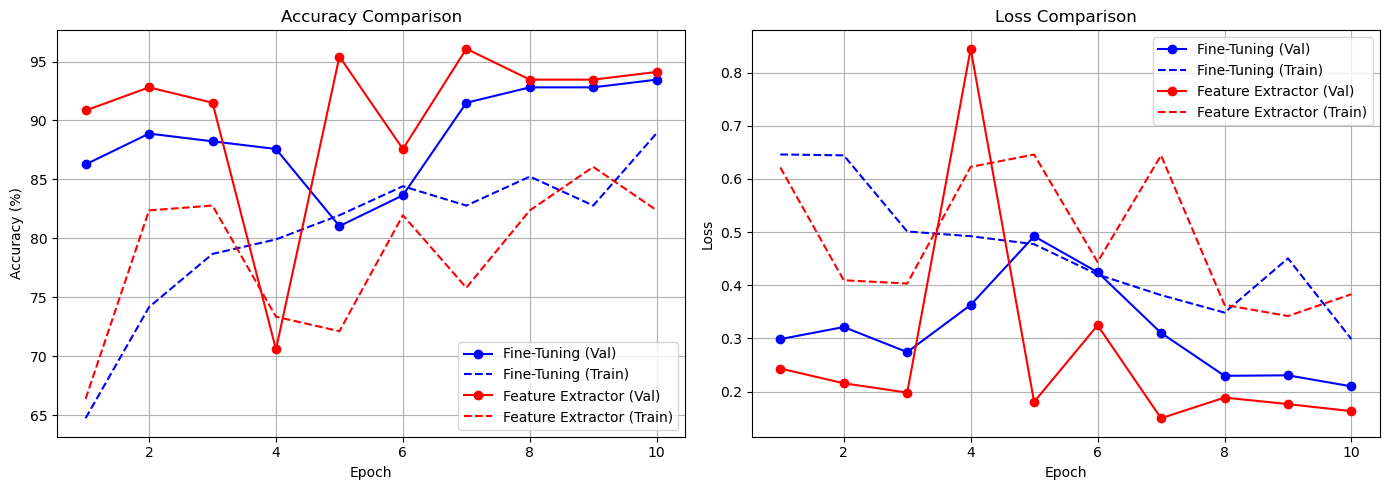


FINAL PERFORMANCE SUMMARY
Fine-Tuning Best Val Accuracy:        93.46%
Feature Extractor Best Val Accuracy:  96.08%


In [3]:
import os
import copy
import time
import zipfile
import urllib.request
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 0. Setup Device and Download Hymenoptera Dataset
# -------------------------------------------------------------------------
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

data_dir = 'hymenoptera_data'
if not os.path.exists(data_dir):
    url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
    zip_path = "hymenoptera_data.zip"
    print("Downloading hymenoptera dataset...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')
    os.remove(zip_path)

# -------------------------------------------------------------------------
# 1. Data Augmentation and DataLoaders
# -------------------------------------------------------------------------
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'val']
}

dataloaders = {
    x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=2)
    for x in ['train', 'val']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes  # ['ants', 'bees']
num_classes = len(class_names)

# -------------------------------------------------------------------------
# 2. Universal Training & Validation Function
# -------------------------------------------------------------------------
def train_model(model, criterion, optimizer, scheduler, num_epochs=10):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        print("-" * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train' and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = (running_corrects.double() / dataset_sizes[phase]).item() * 100

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.2f}%")

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Acc: {best_acc:.2f}%")

    model.load_state_dict(best_model_wts)
    return model, history

criterion = nn.CrossEntropyLoss()
num_epochs = 10

# -------------------------------------------------------------------------
# Part (a): Fine-tuning the Full Network
# -------------------------------------------------------------------------
print("=" * 45)
print("PART (a): Fine-Tuning Entire ResNet-18")
print("=" * 45)

model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, num_classes)  # Replace output layer for 2 classes
model_ft = model_ft.to(device)

# All parameters are updated
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_ft = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, history_ft = train_model(
    model_ft, criterion, optimizer_ft, exp_lr_scheduler_ft, num_epochs=num_epochs
)

# -------------------------------------------------------------------------
# Part (b): Using the Network as a Fixed Feature Extractor
# -------------------------------------------------------------------------
print("\n" + "=" * 45)
print("PART (b): ResNet-18 as Fixed Feature Extractor")
print("=" * 45)

model_conv = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all convolutional backbone parameters
for param in model_conv.parameters():
    param.requires_grad = False

# Newly constructed layer parameters have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, num_classes)
model_conv = model_conv.to(device)

# Only parameters in model_conv.fc are being optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

model_conv, history_conv = train_model(
    model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=num_epochs
)

# -------------------------------------------------------------------------
# 3. Report Results: Comparative Plots & Final Accuracy
# -------------------------------------------------------------------------
epochs_range = range(1, num_epochs + 1)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
axs[0].plot(epochs_range, history_ft['val_acc'], 'b-o', label='Fine-Tuning (Val)')
axs[0].plot(epochs_range, history_ft['train_acc'], 'b--', label='Fine-Tuning (Train)')
axs[0].plot(epochs_range, history_conv['val_acc'], 'r-o', label='Feature Extractor (Val)')
axs[0].plot(epochs_range, history_conv['train_acc'], 'r--', label='Feature Extractor (Train)')
axs[0].set_title('Accuracy Comparison')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy (%)')
axs[0].legend()
axs[0].grid(True)

# Loss Plot
axs[1].plot(epochs_range, history_ft['val_loss'], 'b-o', label='Fine-Tuning (Val)')
axs[1].plot(epochs_range, history_ft['train_loss'], 'b--', label='Fine-Tuning (Train)')
axs[1].plot(epochs_range, history_conv['val_loss'], 'r-o', label='Feature Extractor (Val)')
axs[1].plot(epochs_range, history_conv['train_loss'], 'r--', label='Feature Extractor (Train)')
axs[1].set_title('Loss Comparison')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

print("\n" + "=" * 45)
print("FINAL PERFORMANCE SUMMARY")
print("=" * 45)
print(f"Fine-Tuning Best Val Accuracy:        {max(history_ft['val_acc']):.2f}%")
print(f"Feature Extractor Best Val Accuracy:  {max(history_conv['val_acc']):.2f}%")

### Discussion and interpretation

On the Hymenoptera validation set, fine-tuning all of ResNet-18 reached a best accuracy of **93.46%**. Freezing the pretrained backbone and training only the final layer reached **96.08%**, which is 2.62 percentage points higher, and took less time (about **3m 8s** compared with **3m 58s**). For this small ant-versus-bee dataset, the pretrained features seem to transfer well without needing to update the whole network. Since validation accuracy varies from epoch to epoch, it makes more sense to compare the best scores than to assume the final epoch is the best one.